# Transjakarta - EDA & K-MEANS

### Introduction

Transjakarta, also known as Busway or some people called it TJ, is a Bus Rapid Transit (BRT) system in Jakarta. TJ, Southeast Asia's first BRT system, offer a rapid public transportation solution aimed at alleviating rush hour traffic. The buses operate in dedicated lanes also known as busways, with ticket prices subsidized by the regional goverment. Spanning 251.2 km, TJ boasts the world's longest BRT system, operating around 4,300 buses.

The main objective of this project is to find insights and patterns by looking at how TJ customers behave and try to provide solutions to increase customers. To achieve that goal, this project will perform Explorative Data Analysis and K-Means on Transjakarta customer data.

Source of dataset: [Kaggle-Transjakarta Transportation Transaction](https://www.kaggle.com/datasets/dikisahkan/transjakarta-transportation-transaction)

In [1]:
# Import libraries
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/kaggle/input/transjakarta-transportation-transaction/dfTransjakarta180kRows.csv')

### Data Understanding & Data Preparation

In [3]:
df.head()

,transID,payCardID,payCardBank,payCardName,payCardSex,payCardBirthDate,corridorID,corridorName,direction,tapInStops,...,tapInStopsLon,stopStartSeq,tapInTime,tapOutStops,tapOutStopsName,tapOutStopsLat,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount
0,VRPJ892P3M98RA,3561407960318444,dki,"Dr. Janet Nashiruddin, M.Ak",M,2010,4,Pulo Gadung 2 - Tosari,1.0,P00167,...,106.89165,12,2023-04-03 06:53:02,P00127,Layur,-6.193539,106.89909,13.0,2023-04-03 07:13:28,3500.0
1,ZWCH834I6M26HS,347728053419394,emoney,Balamantri Rahayu,M,2002,JAK.28,Kp. Rambutan - Taman Wiladatika,1.0,B04633P,...,106.86298,27,2023-04-03 05:59:19,B00865P,Jln. Ar Ridho,-6.308148,106.86935,30.0,2023-04-03 06:57:06,0.0
2,YRLD835V6L82GO,377105453850671,emoney,Dian Mustofa,F,1993,B13,Bekasi Barat - Blok M,1.0,B02192P,...,106.99215,6,2023-04-03 05:13:24,B00108P,Bandar Djakarta Bekasi,-6.227085,106.99683,9.0,2023-04-03 06:01:23,20000.0
3,ZZBX143N6N83HQ,4486493302356581,dki,"Cut Janet Suryatmi, M.Ak",M,1980,8K,Batusari - Grogol,1.0,B03637P,...,106.78213,16,2023-04-03 05:20:24,NaN,Yayasan Alkahfi Jakbar,-6.198896,106.76889,26.0,2023-04-03 06:01:25,3500.0
4,EWEG491A2W45DR,30139379978125,bni,"dr. Mulyanto Pudjiastuti, M.Ak",F,1997,NaN,NaN,0.0,NaN,...,106.83514,2,2023-04-03 06:00:54,B02755P,Perpustakaan Nasional,-6.180673,106.82643,5.0,2023-04-03 06:47:32,3500.0


In [4]:
# Check null value and delete if it exists
if df.isna().sum().any():
    print('Null value detected, we will remove it')
    df.dropna(inplace=True)
else:
    pass

Null value detected, we will remove it


In [5]:
df.isna().sum()

transID             0
payCardID           0
payCardBank         0
payCardName         0
payCardSex          0
payCardBirthDate    0
corridorID          0
corridorName        0
direction           0
tapInStops          0
tapInStopsName      0
tapInStopsLat       0
tapInStopsLon       0
stopStartSeq        0
tapInTime           0
tapOutStops         0
tapOutStopsName     0
tapOutStopsLat      0
tapOutStopsLon      0
stopEndSeq          0
tapOutTime          0
payAmount           0
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 153963 entries, 0 to 189499
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transID           153963 non-null  object 
 1   payCardID         153963 non-null  int64  
 2   payCardBank       153963 non-null  object 
 3   payCardName       153963 non-null  object 
 4   payCardSex        153963 non-null  object 
 5   payCardBirthDate  153963 non-null  int64  
 6   corridorID        153963 non-null  object 
 7   corridorName      153963 non-null  object 
 8   direction         153963 non-null  float64
 9   tapInStops        153963 non-null  object 
 10  tapInStopsName    153963 non-null  object 
 11  tapInStopsLat     153963 non-null  float64
 12  tapInStopsLon     153963 non-null  float64
 13  stopStartSeq      153963 non-null  int64  
 14  tapInTime         153963 non-null  object 
 15  tapOutStops       153963 non-null  object 
 16  tapOutStopsName   153963 

In [7]:
df['tapInTime'] = pd.to_datetime(df['tapInTime'])
df['tapOutTime'] = pd.to_datetime(df['tapOutTime'])

In [8]:
df.describe()

,payCardID,payCardBirthDate,direction,tapInStopsLat,tapInStopsLon,stopStartSeq,tapInTime,tapOutStopsLat,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount
count,1.539630e+05,153963.00000,153963.000000,153963.000000,153963.000000,153963.000000,153963,153963.000000,153963.000000,153963.000000,153963,153963.000000
mean,3.950515e+17,1990.14397,0.499451,-6.213629,106.841451,13.499464,2023-04-16 07:46:29.573299968,-6.213512,106.840950,21.079487,2023-04-16 08:58:38.416456960,2675.055046
min,6.040486e+10,1946.00000,0.000000,-6.394973,106.614730,0.000000,2023-04-01 05:14:35,-6.394973,106.614730,1.000000,2023-04-01 06:04:48,0.000000
25%,1.800058e+14,1982.00000,0.000000,-6.246264,106.800940,4.000000,2023-04-10 08:45:29,-6.246510,106.800758,11.000000,2023-04-10 09:54:25.500000,0.000000
50%,3.520356e+15,1991.00000,0.000000,-6.213410,106.837200,10.000000,2023-04-16 16:57:52,-6.212880,106.835470,18.000000,2023-04-16 18:11:56,3500.000000
75%,4.675024e+15,2001.00000,1.000000,-6.173482,106.882450,20.000000,2023-04-21 21:54:04,-6.172158,106.882800,29.000000,2023-04-21 23:35:25.500000,3500.000000
max,4.999814e+18,2012.00000,1.000000,-6.089429,107.023950,75.000000,2023-04-30 21:58:17,-6.089429,107.023840,77.000000,2023-04-30 23:49:48,20000.000000
std,1.273420e+18,13.43743,0.500001,0.058706,0.061167,12.203848,NaN,0.059758,0.061885,13.999448,NaN,4136.652505


In [9]:
df1 = df.copy()

In [10]:
# Extract hour from tapInTime and tapOutTime
df1['tapInHour'] = df1['tapInTime'].dt.hour
df1['tapOutHour'] = df1['tapOutTime'].dt.hour
df1['tapDay'] = df1['tapInTime'].dt.dayofweek
# finding travel duration in minutes
df1['travelDuration'] = df1['tapOutTime'] - df1['tapInTime']
df1['travelDuration'] = df1['travelDuration'].dt.total_seconds()/60
# adding age
df1['payCardAge'] = 2023 - df1['payCardBirthDate']

df1.head()

,transID,payCardID,payCardBank,payCardName,payCardSex,payCardBirthDate,corridorID,corridorName,direction,tapInStops,...,tapOutStopsLat,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount,tapInHour,tapOutHour,tapDay,travelDuration,payCardAge
0,VRPJ892P3M98RA,3561407960318444,dki,"Dr. Janet Nashiruddin, M.Ak",M,2010,4,Pulo Gadung 2 - Tosari,1.0,P00167,...,-6.193539,106.89909,13.0,2023-04-03 07:13:28,3500.0,6,7,0,20.433333,13
1,ZWCH834I6M26HS,347728053419394,emoney,Balamantri Rahayu,M,2002,JAK.28,Kp. Rambutan - Taman Wiladatika,1.0,B04633P,...,-6.308148,106.86935,30.0,2023-04-03 06:57:06,0.0,5,6,0,57.783333,21
2,YRLD835V6L82GO,377105453850671,emoney,Dian Mustofa,F,1993,B13,Bekasi Barat - Blok M,1.0,B02192P,...,-6.227085,106.99683,9.0,2023-04-03 06:01:23,20000.0,5,6,0,47.983333,30
5,KTGG277R2I90ZB,30394281967910,bni,"Dasa Prakasa, S.I.Kom",F,1993,JAK.117,Tanjung Priok - Tanah Merdeka,1.0,B04272P,...,-6.125482,106.89331,21.0,2023-04-03 05:41:04,0.0,5,5,0,35.066667,30
6,VSJU956Z4T24LI,4974829151599657,dki,Elvina Hasanah,M,1966,9F,Rusun Tambora - Pluit,0.0,P00090,...,-6.126306,106.79203,7.0,2023-04-03 06:52:58,0.0,6,6,0,31.850000,57


In [11]:
# Renaming tapDay
df1['tapDay'] = df1['tapDay'].replace(
    {
        0 : 'Monday',
        1 : 'Tuesday',
        2 : 'Wednesday',
        3 : 'Thursday',
        4 : 'Friday',
        5 : 'Saturday',
        6 : 'Sunday'
    }
)
df1['payCardSex'] = df1['payCardSex'].replace(
    {
        'M': 'Male',
        'F': 'Female'
    }
)
df1.head()

,transID,payCardID,payCardBank,payCardName,payCardSex,payCardBirthDate,corridorID,corridorName,direction,tapInStops,...,tapOutStopsLat,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount,tapInHour,tapOutHour,tapDay,travelDuration,payCardAge
0,VRPJ892P3M98RA,3561407960318444,dki,"Dr. Janet Nashiruddin, M.Ak",Male,2010,4,Pulo Gadung 2 - Tosari,1.0,P00167,...,-6.193539,106.89909,13.0,2023-04-03 07:13:28,3500.0,6,7,Monday,20.433333,13
1,ZWCH834I6M26HS,347728053419394,emoney,Balamantri Rahayu,Male,2002,JAK.28,Kp. Rambutan - Taman Wiladatika,1.0,B04633P,...,-6.308148,106.86935,30.0,2023-04-03 06:57:06,0.0,5,6,Monday,57.783333,21
2,YRLD835V6L82GO,377105453850671,emoney,Dian Mustofa,Female,1993,B13,Bekasi Barat - Blok M,1.0,B02192P,...,-6.227085,106.99683,9.0,2023-04-03 06:01:23,20000.0,5,6,Monday,47.983333,30
5,KTGG277R2I90ZB,30394281967910,bni,"Dasa Prakasa, S.I.Kom",Female,1993,JAK.117,Tanjung Priok - Tanah Merdeka,1.0,B04272P,...,-6.125482,106.89331,21.0,2023-04-03 05:41:04,0.0,5,5,Monday,35.066667,30
6,VSJU956Z4T24LI,4974829151599657,dki,Elvina Hasanah,Male,1966,9F,Rusun Tambora - Pluit,0.0,P00090,...,-6.126306,106.79203,7.0,2023-04-03 06:52:58,0.0,6,6,Monday,31.850000,57


### EDA

#### Bank Distribution

In [12]:
# Bank Distribution
customer = df1[[
    'payCardName',
    'payCardAge',
    'payCardBank',
    'payCardSex',
]]

customer.head()

,payCardName,payCardAge,payCardBank,payCardSex
0,"Dr. Janet Nashiruddin, M.Ak",13,dki,Male
1,Balamantri Rahayu,21,emoney,Male
2,Dian Mustofa,30,emoney,Female
5,"Dasa Prakasa, S.I.Kom",30,bni,Female
6,Elvina Hasanah,57,dki,Male


In [13]:
bank_dist = customer['payCardBank'].value_counts().reset_index(name='count')
bank_dist

,payCardBank,count
0,dki,77519
1,emoney,24875
2,brizzi,13422
3,bni,12870
4,online,12858
5,flazz,12419


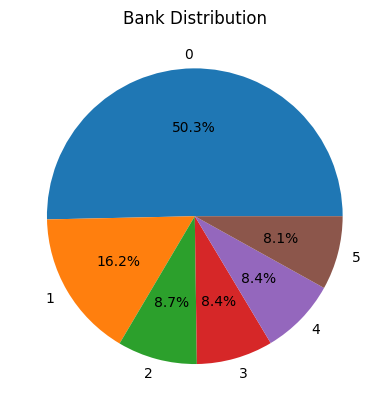

In [14]:
# Create pie chart
plt.pie(bank_dist['count'], labels=bank_dist.index,autopct='%1.1f%%')
plt.title('Bank Distribution')
plt.show()

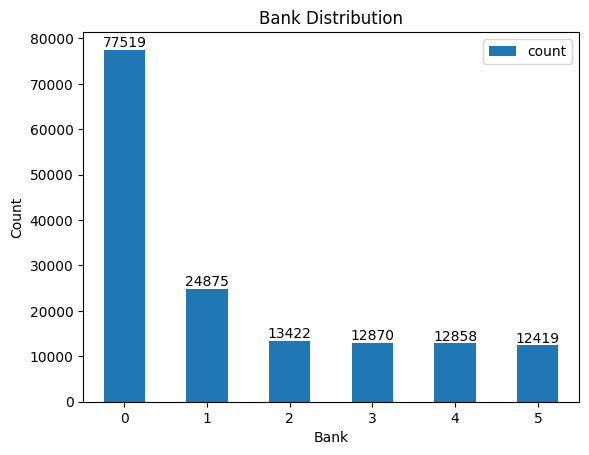

In [15]:
bank_dist.reset_index(inplace=True)
# Create a bar
ax = bank_dist.plot(x='index', kind='bar')
# Adding text
for i, val in enumerate(bank_dist['count']):
    ax.text(i, val, str(val), ha='center', va='bottom')

plt.xlabel('Bank')
plt.ylabel('Count')
plt.title('Bank Distribution')
plt.xticks(rotation=0)
plt.show()

#### Age Distribution

In [16]:
customer

,payCardName,payCardAge,payCardBank,payCardSex
0,"Dr. Janet Nashiruddin, M.Ak",13,dki,Male
1,Balamantri Rahayu,21,emoney,Male
2,Dian Mustofa,30,emoney,Female
5,"Dasa Prakasa, S.I.Kom",30,bni,Female
6,Elvina Hasanah,57,dki,Male
...,...,...,...,...
189495,"R.A. Malika Samosir, S.Kom",25,emoney,Male
189496,Amalia Gunarto,42,dki,Male
189497,R.A. Lintang Wibisono,25,brizzi,Female
189498,Yunita Sitompul,39,online,Female


In [17]:
# Grouping customer age
customer_age = customer[['payCardName','payCardAge']].copy()

bins = [10, 20, 31, 40, 50, 60, 70, 80]
labels = ['10-19','20-29','30-39','40-49','50-59','60-69','70+']
customer_age['age_range']=pd.cut(customer_age['payCardAge'], bins=bins, labels=labels,include_lowest=True)

customer_age_counted = customer_age['age_range'].value_counts().reset_index(name='count')
customer_age_counted

,age_range,count
0,30-39,41116
1,20-29,40416
2,10-19,32845
3,40-49,21574
4,50-59,14336
5,60-69,2040
6,70+,1636


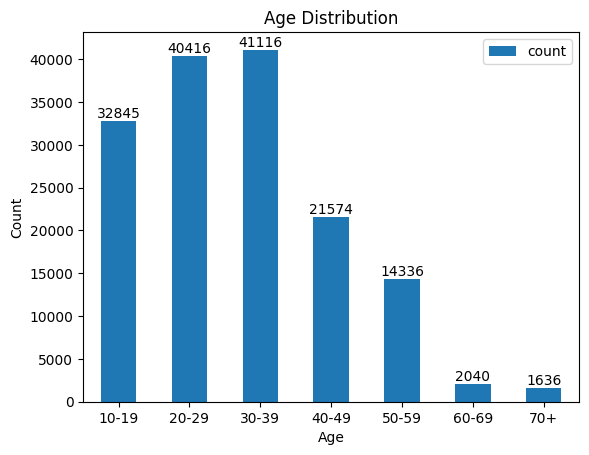

In [18]:
# Visualize with bar chart
customer_age_sorted = customer_age_counted.sort_values(by='age_range')

ax = customer_age_sorted.plot(x='age_range', y='count' , kind='bar')
for i, val in enumerate(customer_age_sorted['count']):
    ax.text(i,val,str(val),ha='center', va='bottom')

plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age Distribution')
plt.xticks(rotation=0)
plt.show()

In [19]:
df1.head()

,transID,payCardID,payCardBank,payCardName,payCardSex,payCardBirthDate,corridorID,corridorName,direction,tapInStops,...,tapOutStopsLat,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount,tapInHour,tapOutHour,tapDay,travelDuration,payCardAge
0,VRPJ892P3M98RA,3561407960318444,dki,"Dr. Janet Nashiruddin, M.Ak",Male,2010,4,Pulo Gadung 2 - Tosari,1.0,P00167,...,-6.193539,106.89909,13.0,2023-04-03 07:13:28,3500.0,6,7,Monday,20.433333,13
1,ZWCH834I6M26HS,347728053419394,emoney,Balamantri Rahayu,Male,2002,JAK.28,Kp. Rambutan - Taman Wiladatika,1.0,B04633P,...,-6.308148,106.86935,30.0,2023-04-03 06:57:06,0.0,5,6,Monday,57.783333,21
2,YRLD835V6L82GO,377105453850671,emoney,Dian Mustofa,Female,1993,B13,Bekasi Barat - Blok M,1.0,B02192P,...,-6.227085,106.99683,9.0,2023-04-03 06:01:23,20000.0,5,6,Monday,47.983333,30
5,KTGG277R2I90ZB,30394281967910,bni,"Dasa Prakasa, S.I.Kom",Female,1993,JAK.117,Tanjung Priok - Tanah Merdeka,1.0,B04272P,...,-6.125482,106.89331,21.0,2023-04-03 05:41:04,0.0,5,5,Monday,35.066667,30
6,VSJU956Z4T24LI,4974829151599657,dki,Elvina Hasanah,Male,1966,9F,Rusun Tambora - Pluit,0.0,P00090,...,-6.126306,106.79203,7.0,2023-04-03 06:52:58,0.0,6,6,Monday,31.850000,57


#### Gender Distribution

In [20]:
gender_df = df1['payCardSex'].value_counts().reset_index(name='count')
gender_df

,payCardSex,count
0,Female,82829
1,Male,71134


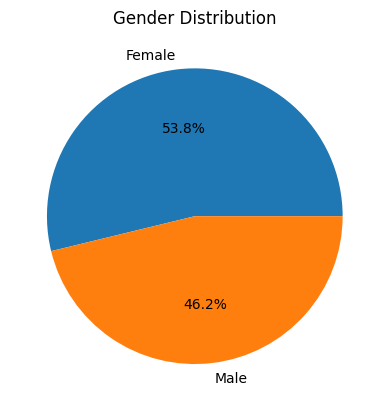

In [21]:
# Visualize with pie chart
plt.pie(gender_df['count'], labels=gender_df['payCardSex'],autopct='%1.1f%%')
plt.title('Gender Distribution')
plt.show()

#### Peak Day & Rush Hour Distribution

In [22]:
day_df = df1['tapDay'].value_counts().reset_index(name='count')
day_df

,tapDay,count
0,Thursday,27865
1,Friday,27812
2,Tuesday,27808
3,Monday,27743
4,Wednesday,27732
5,Saturday,7526
6,Sunday,7477


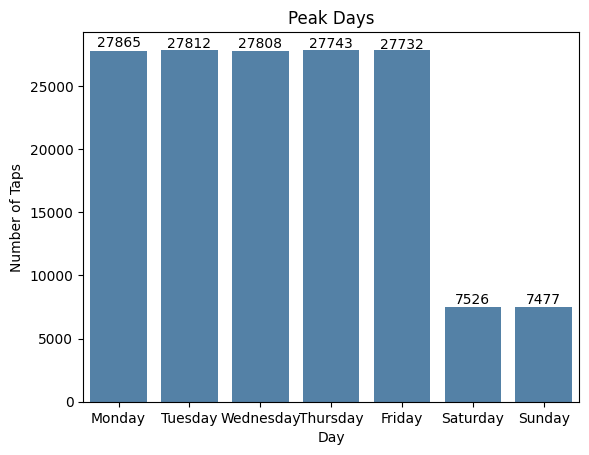

In [23]:
day_order = ['Monday', 'Tuesday', 'Wednesday','Thursday','Friday','Saturday', 'Sunday']
# Visualize
ax = sns.barplot(x='tapDay',y='count',data=day_df, order=day_order,color='steelblue')
# Label
for i, val in enumerate(day_df['count']):
    ax.text(i,val,str(val),ha='center',va='bottom')

plt.title('Peak Days')
plt.xlabel('Day')
plt.ylabel('Number of Taps')
plt.xticks(rotation=0)
plt.show()

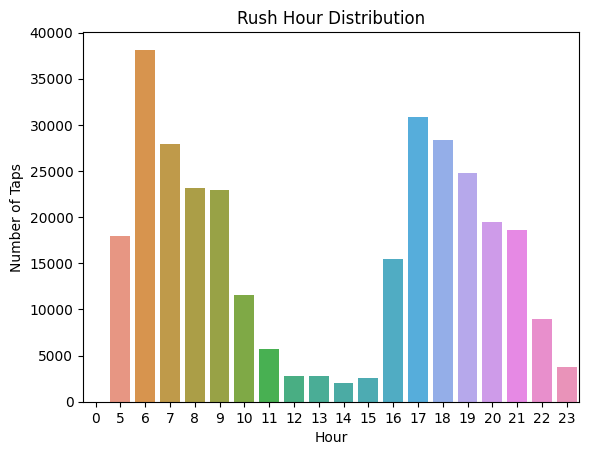

In [24]:
# Make a Copy of df1, Groupby TapIn/TapOut, and Calculate Taps
travelduration = df1.copy()

tapin_counts=travelduration.groupby('tapInHour')['payCardID'].count()
tapout_counts=travelduration.groupby('tapOutHour')['payCardID'].count()
# Combine both the counts
count_hours_combine = tapin_counts.add(tapout_counts, fill_value=0)

count_hours_df= count_hours_combine.reset_index()
count_hours_df.columns = ['Hour', 'Count']

# Visualize with a bar chart
sns.barplot(x='Hour',y='Count',data=count_hours_df)
plt.title('Rush Hour Distribution')
plt.xlabel('Hour')
plt.ylabel('Number of Taps')
plt.xticks(rotation=0)
plt.show()

#### Stops Statistics

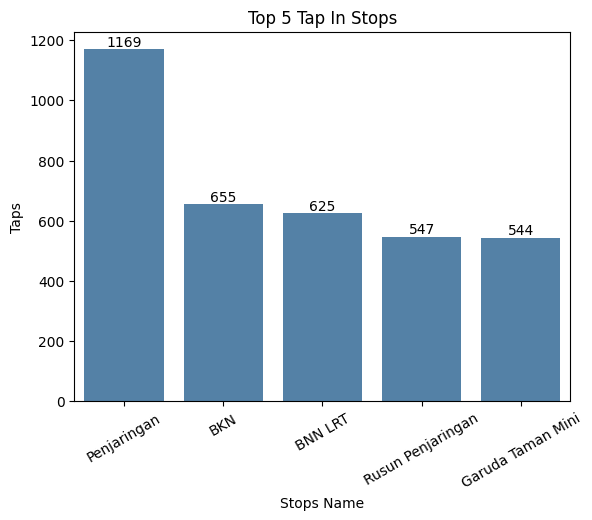

In [25]:
TapInStation = df1['tapInStopsName'].value_counts().reset_index(name='transaction')
# Visualize
ax = sns.barplot(x='tapInStopsName', y='transaction',data=TapInStation.head(5), color='steelblue')

for i, val in enumerate(TapInStation.head(5)['transaction']):
    ax.text(i,val,str(val),ha='center',va='bottom')

plt.xlabel('Stops Name')
plt.ylabel('Taps')
plt.title('Top 5 Tap In Stops')
plt.xticks(rotation=30)
plt.show()

In [26]:
TapInStats = df1.groupby(['tapInStopsName','tapInHour'])['tapInStops'].count().reset_index()
TapInStats = TapInStats.sort_values('tapInStops', ascending = False, ignore_index= True)
TapInStats.head(5)

,tapInStopsName,tapInHour,tapInStops
0,Penjaringan,17,205
1,BKN,6,155
2,Penjaringan,6,150
3,Penjaringan,16,131
4,BNN LRT,17,118


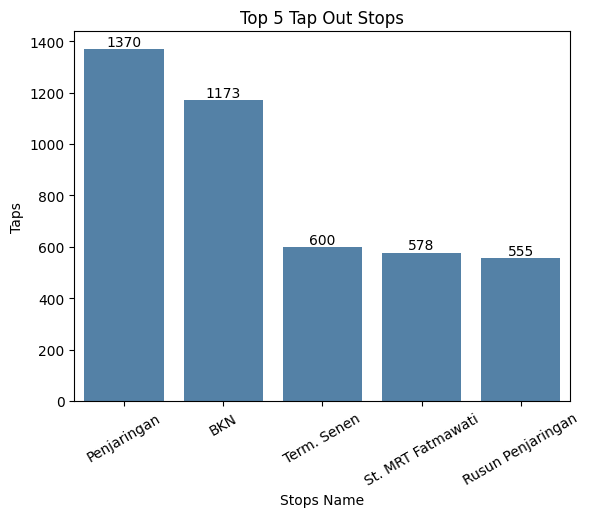

In [27]:
TapOutStation = df1['tapOutStopsName'].value_counts().reset_index(name='transaction')
# Visualize
ax = sns.barplot(x='tapOutStopsName', y='transaction', data=TapOutStation.head(5) ,color='steelblue')

for i, val in enumerate(TapOutStation.head(5)['transaction']):
    ax.text(i,val,str(val),ha='center',va='bottom')

plt.xlabel('Stops Name')
plt.ylabel('Taps')
plt.title('Top 5 Tap Out Stops')
plt.xticks(rotation=30)
plt.show()

In [28]:
TapOutStats = df1.groupby(['tapOutStopsName','tapOutHour'])['tapOutStops'].count().reset_index()
TapOutStats = TapOutStats.sort_values('tapOutStops', ascending = False, ignore_index= True)
TapOutStats.head(5)

,tapOutStopsName,tapOutHour,tapOutStops
0,Penjaringan,6,201
1,BKN,18,175
2,Penjaringan,7,171
3,Penjaringan,18,144
4,BKN,7,132


#### Payment Amount Distribution

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


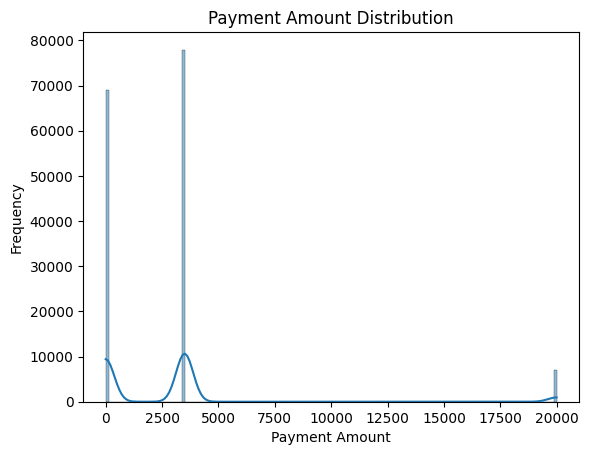

In [29]:
payment_distribution = df1.copy()
sns.histplot(payment_distribution['payAmount'], kde=True)
plt.xlabel('Payment Amount')
plt.ylabel('Frequency')
plt.title('Payment Amount Distribution')
plt.show()

#### Correlation

In [30]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 153963 entries, 0 to 189499
Data columns (total 27 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transID           153963 non-null  object        
 1   payCardID         153963 non-null  int64         
 2   payCardBank       153963 non-null  object        
 3   payCardName       153963 non-null  object        
 4   payCardSex        153963 non-null  object        
 5   payCardBirthDate  153963 non-null  int64         
 6   corridorID        153963 non-null  object        
 7   corridorName      153963 non-null  object        
 8   direction         153963 non-null  float64       
 9   tapInStops        153963 non-null  object        
 10  tapInStopsName    153963 non-null  object        
 11  tapInStopsLat     153963 non-null  float64       
 12  tapInStopsLon     153963 non-null  float64       
 13  stopStartSeq      153963 non-null  int64         
 14  tapInTime

In [31]:
df1.describe()

,payCardID,payCardBirthDate,direction,tapInStopsLat,tapInStopsLon,stopStartSeq,tapInTime,tapOutStopsLat,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount,tapInHour,tapOutHour,travelDuration,payCardAge
count,1.539630e+05,153963.00000,153963.000000,153963.000000,153963.000000,153963.000000,153963,153963.000000,153963.000000,153963.000000,153963,153963.000000,153963.000000,153963.000000,153963.000000,153963.00000
mean,3.950515e+17,1990.14397,0.499451,-6.213629,106.841451,13.499464,2023-04-16 07:46:29.573299968,-6.213512,106.840950,21.079487,2023-04-16 08:58:38.416456960,2675.055046,12.513383,13.714685,72.147386,32.85603
min,6.040486e+10,1946.00000,0.000000,-6.394973,106.614730,0.000000,2023-04-01 05:14:35,-6.394973,106.614730,1.000000,2023-04-01 06:04:48,0.000000,5.000000,0.000000,15.000000,11.00000
25%,1.800058e+14,1982.00000,0.000000,-6.246264,106.800940,4.000000,2023-04-10 08:45:29,-6.246510,106.800758,11.000000,2023-04-10 09:54:25.500000,0.000000,7.000000,8.000000,51.083333,22.00000
50%,3.520356e+15,1991.00000,0.000000,-6.213410,106.837200,10.000000,2023-04-16 16:57:52,-6.212880,106.835470,18.000000,2023-04-16 18:11:56,3500.000000,13.000000,14.000000,71.766667,32.00000
75%,4.675024e+15,2001.00000,1.000000,-6.173482,106.882450,20.000000,2023-04-21 21:54:04,-6.172158,106.882800,29.000000,2023-04-21 23:35:25.500000,3500.000000,17.000000,19.000000,95.983333,41.00000
max,4.999814e+18,2012.00000,1.000000,-6.089429,107.023950,75.000000,2023-04-30 21:58:17,-6.089429,107.023840,77.000000,2023-04-30 23:49:48,20000.000000,21.000000,23.000000,180.000000,77.00000
std,1.273420e+18,13.43743,0.500001,0.058706,0.061167,12.203848,NaN,0.059758,0.061885,13.999448,NaN,4136.652505,5.713928,5.951606,28.124424,13.43743


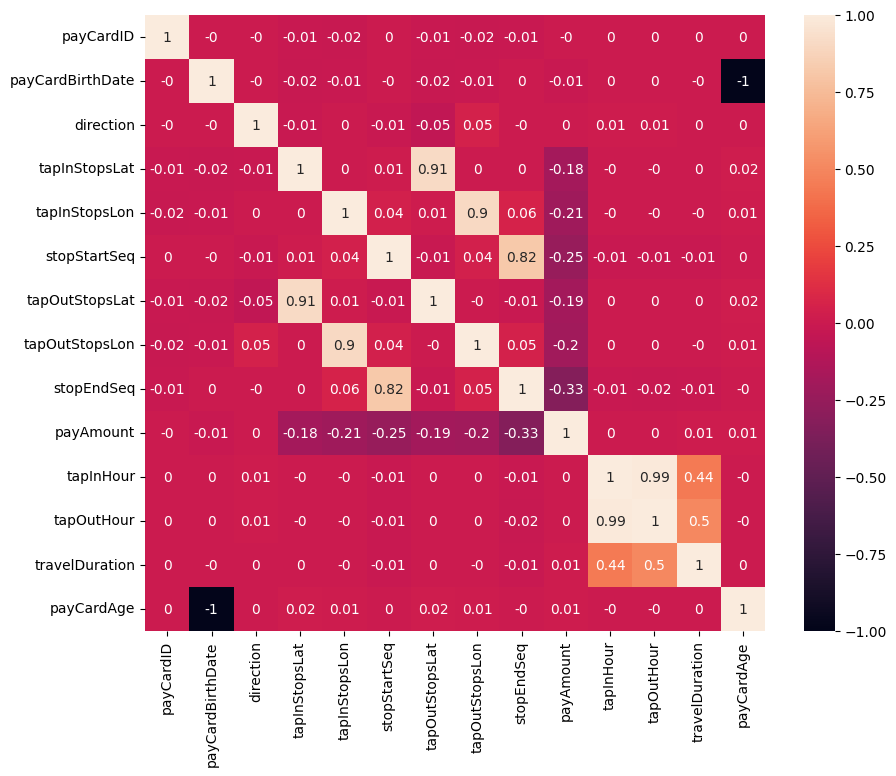

In [32]:
tj_correlation = df1.corr(numeric_only=True).round(2)
tj_correlation

plt.figure(figsize=(10,8))
plot = sns.heatmap(tj_correlation, annot = True)

### K-MEANS

In [33]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
from mpl_toolkits.mplot3d import Axes3D

In [34]:
clv = df1[['payCardName', 'tapOutTime', 'payAmount']]
clv

,payCardName,tapOutTime,payAmount
0,"Dr. Janet Nashiruddin, M.Ak",2023-04-03 07:13:28,3500.0
1,Balamantri Rahayu,2023-04-03 06:57:06,0.0
2,Dian Mustofa,2023-04-03 06:01:23,20000.0
5,"Dasa Prakasa, S.I.Kom",2023-04-03 05:41:04,0.0
6,Elvina Hasanah,2023-04-03 06:52:58,0.0
...,...,...,...
189495,"R.A. Malika Samosir, S.Kom",2023-04-02 14:54:30,0.0
189496,Amalia Gunarto,2023-04-04 18:38:31,3500.0
189497,R.A. Lintang Wibisono,2023-04-05 12:20:28,3500.0
189498,Yunita Sitompul,2023-04-14 16:05:12,3500.0


In [35]:
# Calculate Recency

max_date = clv['tapOutTime'].max()
clv.loc[:, 'recency'] = max_date - clv['tapOutTime']
clv.loc[:, 'recency'] = clv['recency'].dt.days
clv

/tmp/ipykernel_19/884926757.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clv.loc[:, 'recency'] = max_date - clv['tapOutTime']
/tmp/ipykernel_19/884926757.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[27 27 27 ... 25 16  1]' has dtype incompatible with timedelta64[ns], please explicitly cast to a compatible dtype first.
  clv.loc[:, 'recency'] = clv['recency'].dt.days


,payCardName,tapOutTime,payAmount,recency
0,"Dr. Janet Nashiruddin, M.Ak",2023-04-03 07:13:28,3500.0,27
1,Balamantri Rahayu,2023-04-03 06:57:06,0.0,27
2,Dian Mustofa,2023-04-03 06:01:23,20000.0,27
5,"Dasa Prakasa, S.I.Kom",2023-04-03 05:41:04,0.0,27
6,Elvina Hasanah,2023-04-03 06:52:58,0.0,27
...,...,...,...,...
189495,"R.A. Malika Samosir, S.Kom",2023-04-02 14:54:30,0.0,28
189496,Amalia Gunarto,2023-04-04 18:38:31,3500.0,26
189497,R.A. Lintang Wibisono,2023-04-05 12:20:28,3500.0,25
189498,Yunita Sitompul,2023-04-14 16:05:12,3500.0,16


In [36]:
# Calculate Frequency (F)
frequency = clv['payCardName'].value_counts().reset_index()
frequency.columns = ['payCardName', 'frequency']

# Merge frequency back into the original DataFrame
clv = clv.merge(frequency, on='payCardName', how='left')
clv


,payCardName,tapOutTime,payAmount,recency,frequency
0,"Dr. Janet Nashiruddin, M.Ak",2023-04-03 07:13:28,3500.0,27,36
1,Balamantri Rahayu,2023-04-03 06:57:06,0.0,27,37
2,Dian Mustofa,2023-04-03 06:01:23,20000.0,27,35
3,"Dasa Prakasa, S.I.Kom",2023-04-03 05:41:04,0.0,27,31
4,Elvina Hasanah,2023-04-03 06:52:58,0.0,27,34
...,...,...,...,...,...
153958,"R.A. Malika Samosir, S.Kom",2023-04-02 14:54:30,0.0,28,1
153959,Amalia Gunarto,2023-04-04 18:38:31,3500.0,26,1
153960,R.A. Lintang Wibisono,2023-04-05 12:20:28,3500.0,25,1
153961,Yunita Sitompul,2023-04-14 16:05:12,3500.0,16,1


In [37]:
# Calculate Customer Lifetime Value (CLV)
calculated_clv = clv.groupby('payCardName')['payAmount'].sum().reset_index().sort_values('payAmount', ascending=False,ignore_index=True)
calculated_clv


,payCardName,payAmount
0,Aisyah Nainggolan,780000.0
1,Zamira Hutapea,760000.0
2,Balidin Irawan,760000.0
3,Ade Yolanda,740000.0
4,Ulva Laksita,740000.0
...,...,...
9444,Laila Mandasari,0.0
9445,Laila Pradipta,0.0
9446,Laila Suryatmi,0.0
9447,Laksana Nashiruddin,0.0


In [38]:
# Drop duplicate on payCardName and tapOutTime and payAmount column
clv.drop_duplicates(subset='payCardName', keep='first', inplace=True)
clv.drop(columns=['tapOutTime', 'payAmount'], inplace=True)
#clv
# Merge with calculated_clv
clv = clv.merge(calculated_clv, on='payCardName', how='left')
clv

,payCardName,recency,frequency,payAmount
0,"Dr. Janet Nashiruddin, M.Ak",27,36,126000.0
1,Balamantri Rahayu,27,37,0.0
2,Dian Mustofa,27,35,700000.0
3,"Dasa Prakasa, S.I.Kom",27,31,0.0
4,Elvina Hasanah,27,34,0.0
...,...,...,...,...
9444,"R.A. Malika Samosir, S.Kom",28,1,0.0
9445,Amalia Gunarto,26,1,3500.0
9446,R.A. Lintang Wibisono,25,1,3500.0
9447,Yunita Sitompul,16,1,3500.0


In [39]:
# rename column
clv.rename(columns={'payAmount': 'value'}, inplace=True)
clv

,payCardName,recency,frequency,value
0,"Dr. Janet Nashiruddin, M.Ak",27,36,126000.0
1,Balamantri Rahayu,27,37,0.0
2,Dian Mustofa,27,35,700000.0
3,"Dasa Prakasa, S.I.Kom",27,31,0.0
4,Elvina Hasanah,27,34,0.0
...,...,...,...,...
9444,"R.A. Malika Samosir, S.Kom",28,1,0.0
9445,Amalia Gunarto,26,1,3500.0
9446,R.A. Lintang Wibisono,25,1,3500.0
9447,Yunita Sitompul,16,1,3500.0


In [40]:
km_data = clv
scale = ['recency', 'frequency', 'value']
scaler = MinMaxScaler()
km_data[scale] = scaler.fit_transform(km_data[scale])
km_data

,payCardName,recency,frequency,value
0,"Dr. Janet Nashiruddin, M.Ak",0.931034,0.492958,0.161538
1,Balamantri Rahayu,0.931034,0.507042,0.000000
2,Dian Mustofa,0.931034,0.478873,0.897436
3,"Dasa Prakasa, S.I.Kom",0.931034,0.422535,0.000000
4,Elvina Hasanah,0.931034,0.464789,0.000000
...,...,...,...,...
9444,"R.A. Malika Samosir, S.Kom",0.965517,0.000000,0.000000
9445,Amalia Gunarto,0.896552,0.000000,0.004487
9446,R.A. Lintang Wibisono,0.862069,0.000000,0.004487
9447,Yunita Sitompul,0.551724,0.000000,0.004487


/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:8

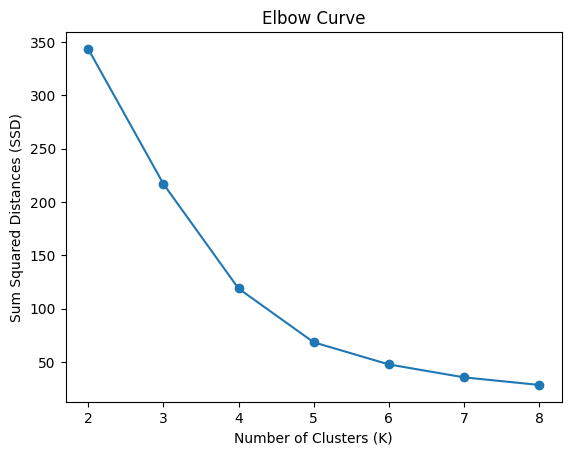

In [41]:
# define range of cluster ( from 2 to 9)
range_n_clusters = range(2, 9)

# Calculate Sum of Squared Distances (SSD)
ssd = []
for n_clusters in range_n_clusters:
    kmeans = KMeans(n_clusters=n_clusters)
    kmeans.fit(km_data[['recency','frequency','value']])
    ssd.append(kmeans.inertia_)

# Plot the elbow curve
plt.plot(range_n_clusters, ssd, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Sum Squared Distances (SSD)')
plt.title('Elbow Curve')
plt.show()

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:8

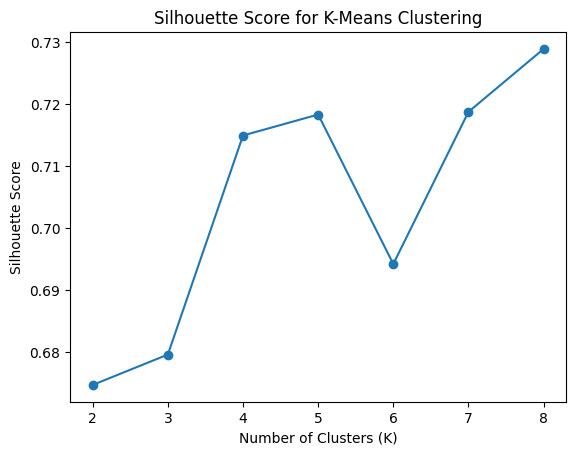

In [42]:
# Define range of clusters to try (from 2 to 10)
range_n_clusters = range(2, 9)

# Calculate Silhouette Score for each value of K
silhouette_scores = []
for n_clusters in range_n_clusters:
    kmeans = KMeans(n_clusters=n_clusters)
    kmeans.fit(km_data[['recency','frequency','value']])
    cluster_labels = kmeans.labels_
    silhouette_avg = silhouette_score(km_data[['recency','frequency','value']], cluster_labels)
    silhouette_scores.append(silhouette_avg)

# Plot the silhouette scores
plt.plot(range_n_clusters, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for K-Means Clustering')
plt.show()

In [43]:
ssd

[343.3641455239515,
 216.93483565738126,
 118.8292160954622,
 68.43790094171223,
 47.667954730974806,
 35.553890900875544,
 28.45404462390656]

In [44]:
# Perform K-Means Clustering with 4 clusters (k=4)
kmeans = KMeans(n_clusters=4)
km_data['cluster'] = kmeans.fit_predict(km_data[['recency','frequency','value']])
km_data

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


,payCardName,recency,frequency,value,cluster
0,"Dr. Janet Nashiruddin, M.Ak",0.931034,0.492958,0.161538,1
1,Balamantri Rahayu,0.931034,0.507042,0.000000,1
2,Dian Mustofa,0.931034,0.478873,0.897436,3
3,"Dasa Prakasa, S.I.Kom",0.931034,0.422535,0.000000,1
4,Elvina Hasanah,0.931034,0.464789,0.000000,1
...,...,...,...,...,...
9444,"R.A. Malika Samosir, S.Kom",0.965517,0.000000,0.000000,0
9445,Amalia Gunarto,0.896552,0.000000,0.004487,0
9446,R.A. Lintang Wibisono,0.862069,0.000000,0.004487,0
9447,Yunita Sitompul,0.551724,0.000000,0.004487,0


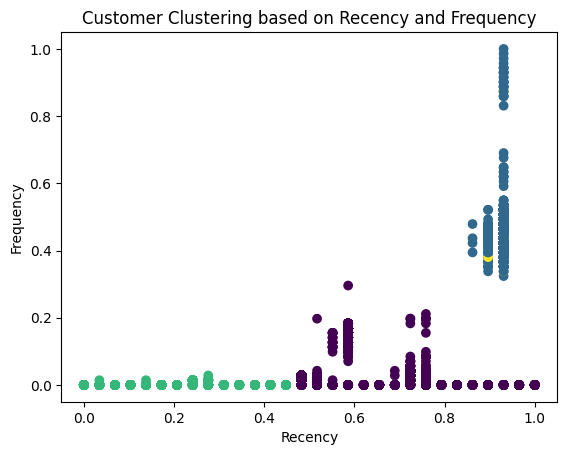

In [45]:
# Scatter plot based on recency and frequency
plt.scatter(km_data['recency'], km_data['frequency'], c=km_data['cluster'])
plt.xlabel('Recency')
plt.ylabel('Frequency')
plt.title('Customer Clustering based on Recency and Frequency')
plt.show()

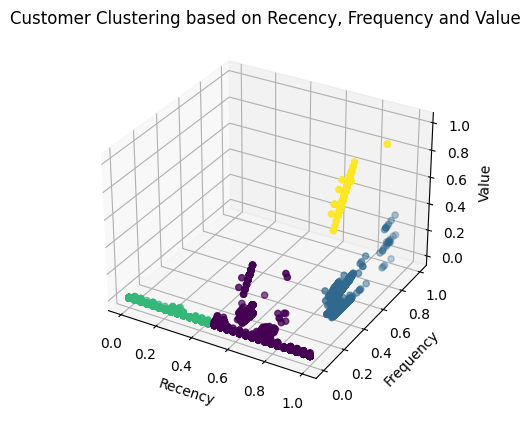

In [46]:
# Scatter plot based on recency, frequency and value
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(km_data['recency'], km_data['frequency'], km_data['value'], c=km_data['cluster'])
ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
ax.set_zlabel('Value')
ax.set_title('Customer Clustering based on Recency, Frequency and Value')
plt.show()

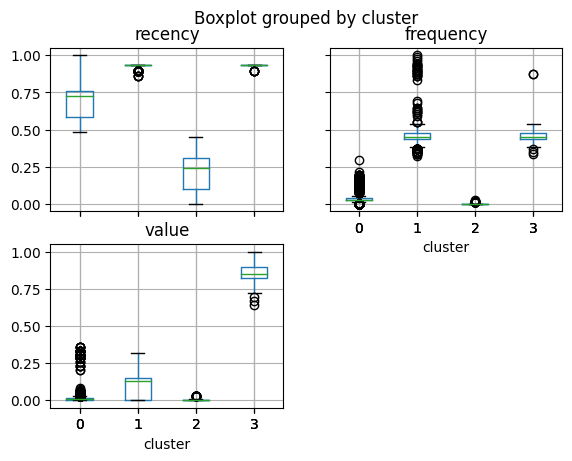

In [47]:
# Boxplot for Recency, Frequency, and Value
km_data.boxplot(column=['recency', 'frequency', 'value'], by='cluster')
plt.show()

In [48]:
km_data.groupby('cluster').describe().transpose()

cluster                    0            1           2           3
recency   count  4906.000000  3722.000000  648.000000  173.000000
          mean      0.685586     0.930006    0.218444    0.929839
          std       0.106551     0.006080    0.131731    0.006328
          min       0.482759     0.862069    0.000000    0.896552
          25%       0.586207     0.931034    0.103448    0.931034
          50%       0.724138     0.931034    0.241379    0.931034
          75%       0.758621     0.931034    0.310345    0.931034
          max       1.000000     0.931034    0.448276    0.931034
frequency count  4906.000000  3722.000000  648.000000  173.000000
          mean      0.051636     0.457239    0.001630    0.457706
          std       0.051405     0.053038    0.004577    0.056248
          min       0.000000     0.323944    0.000000    0.338028
          25%       0.028169     0.436620    0.000000    0.436620
          50%       0.028169     0.450704    0.000000    0.450704
          75%       0.042254     0.478873    0.000000    0.478873
          max       0.295775     1.000000    0.028169    0.873239
value     count  4906.000000  3722.000000  648.000000  173.000000
          mean      0.016670     0.079694    0.003851    0.850437
          std       0.034631     0.075360    0.006021    0.061279
          min       0.000000     0.000000    0.000000    0.641026
          25%       0.004487     0.000000    0.000000    0.820513
          50%       0.008974     0.130128    0.004487    0.846154
          75%       0.013462     0.152564    0.004487    0.897436
          max       0.358974     0.318590    0.030128    1.000000

In [49]:
# finding mean
mean_summary = km_data[['cluster','recency','frequency','value']]
mean_summary.groupby('cluster').mean()

,recency,frequency,value
cluster,,,
0,0.685586,0.051636,0.016670
1,0.930006,0.457239,0.079694
2,0.218444,0.001630,0.003851
3,0.929839,0.457706,0.850437


| Cluster | Customer Type | RFM Characteristics | Action |
|----------|----------|----------|----------|
| 0  | 	General Potential Customers   | Pengguna yang yang memiliki interaksi cukup terbaru dengan layanan Transjakarta <br> (Medium to High Recency), frekuensi menggunakan layanan rendah (Low Frequency), <br> dan menghabiskan uang yang sedikit ketika mennggunakan layanan (Low Monetary) | Dorong pengguna tipe ini dengan <br> memberikan promosi dan penawaran khusus <br> yang relevan atau dengan menawarkan <br> subscription program (Daily/Weekly/Monthly/Seasonal Payment)|
| 1   | General Valuable Customers   | Pengguna yang memiliki interaksi terbaru dengan layanan Transjakarta (High Recency), <br> frekuensi menggunakan layanan tinggi (High Frequency), <br> dan menghabiskan uang yang sedikit ketika menggunakan layanan (Low Monetary) | Dorong pengguna ini untuk meningkatkan <br> nilai transaksi dengan memberikan program penawaran <br> khusus untuk pengguna loyal, atau dengan menawarkan <br> subscription program (Daily/Weekly/Monthly/Seasonal Payment)   |
| 2   | General At Risk Customers   | Pengguna yang memiliki interaksi cukup dengan layanan transjakarta (Medium to Low Recency), <br> frekuensi menggunakan layanan rendah (Low Frequency), <br> dan menghabiskan uang yag sedikit ketika menggunakan layanan (Low Moneary)   | Dorong pengguna ini untuk meningkatkan nilai transaksi dengan <br> memberikan program penawaran khusus untuk pengguna lama <br> untuk meningkatkan spending value atau dengan menawarkan <br> subscription program (Daily/Weekly/Monthly/Seasonal Payment)   |
| 3   | Key Valueable Customers   | Pengguna yang memiliki interaksi terbaru dengan layanan Transjakarta (High Recency), <br> frekuensi menggunakan layanan yang tinggi  (High Frequency), dan telah menghabiskan <br> banyak uang (spend money) dalam menggunakan layanan  | Fokus untuk mempertahankan customer ini dengan <br> memberikan  program loyalitas dan reward berupa penawaran spesial (special offers)   |

